In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from utils import (
    calculate_cost_basis_per_time,
    allocate_weekly_investment,
    get_decay_rate,
    compute_effective_annual_rate,
    compute_portfolio_effective_annual_return,
)

In [2]:
# Read AAII.xlsx with header on row 1 (index 1)
aaii_df = pd.read_excel('AAII.xlsx', header=1)

In [3]:
# Read TransactionHistory.xlsx
transactions_df = pd.read_excel('TransactionHistory.xlsx')

In [4]:
# Read deleted_shadow_stocks.txt
with open('deleted_shadow_stocks.txt', 'r') as f:
    deleted_stocks = [line.strip() for line in f if line.strip()]

# Get list of valid tickers from AAII (excluding deleted stocks)
valid_tickers = set(aaii_df['Ticker'].dropna().unique())
valid_tickers = valid_tickers - set(deleted_stocks)

# Filter transactions to only include stocks in AAII (and not deleted)
filtered_transactions = transactions_df[transactions_df['Symbol'].isin(valid_tickers)].copy()

In [5]:
# Convert date columns to datetime with mixed format handling
filtered_transactions['Activity/Trade Date'] = pd.to_datetime(filtered_transactions['Activity/Trade Date'], format='mixed')
filtered_transactions['Transaction Date'] = pd.to_datetime(filtered_transactions['Transaction Date'], format='mixed')
filtered_transactions['Settlement Date'] = pd.to_datetime(filtered_transactions['Settlement Date'], format='mixed')

# Parse activity type to identify buys and sells
print("Activity Type values:")
print(filtered_transactions['Activity Type'].value_counts())

Activity Type values:
Activity Type
Bought                984
0                     474
Dividend               87
Qualified Dividend     66
Stock Split             1
Name: count, dtype: int64


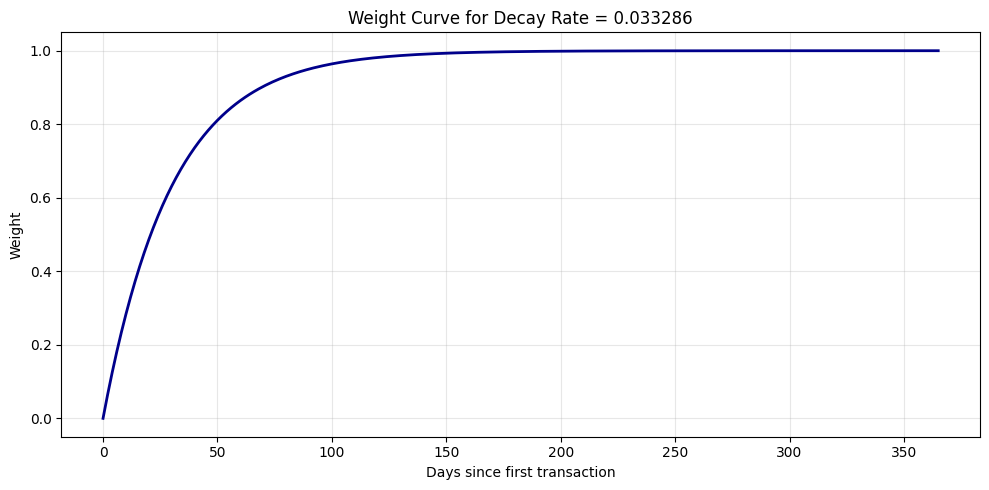

Cost basis per time:
   Ticker  Total Buy Cost  Total Sell Proceeds  Total Dividend Payout  \
0     FRD         1678.70                 0.00                  14.73   
1     SND          871.46                 0.00                   0.00   
2    JRSH          898.40                 0.00                   0.00   
3    AMPY         1506.79                 0.00                   0.00   
4    GASS         1504.95                 0.00                   0.00   
5     EBF         1541.00                 0.00                 123.88   
6     RGS         1557.66                 0.00                   0.00   
7    ESCA         1502.45                 0.00                  71.16   
8    GILT         1490.64                 0.00                   0.00   
9    CTRM         1490.38                 0.00                   0.00   
10    EML         1485.89                 0.00                  12.02   
11   KGEI         1354.85                 0.00                   0.00   
12   RCKY         1530.63     

In [6]:
decay_rate = get_decay_rate(90, 180, 0.05)  # Example: 50% decay over 90 to 180 days

# Plot the decay weight curve for the chosen decay rate
days_since_first_transaction = np.arange(0, 366, 1)
weight_curve = 1 - np.exp(-decay_rate * days_since_first_transaction)

plt.figure(figsize=(10, 5))
plt.plot(days_since_first_transaction, weight_curve, color='darkblue', linewidth=2)
plt.xlabel('Days since first transaction')
plt.ylabel('Weight')
plt.title(f'Weight Curve for Decay Rate = {decay_rate:.6f}')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

reference_date = pd.Timestamp.now() + pd.Timedelta(days=7)  # 7 days from present
cost_basis_df = calculate_cost_basis_per_time(filtered_transactions, decay_rate=decay_rate, reference_date=reference_date)
print("Cost basis per time:")
print(cost_basis_df)
print("\nDividend payouts by stock:")
print(cost_basis_df[['Ticker', 'Total Dividend Payout']].sort_values('Total Dividend Payout', ascending=False))

# Allocate weekly investment
weekly_new_amount = 350
allocation_df, updated_cost_basis_df = allocate_weekly_investment(cost_basis_df, aaii_df, weekly_new_amount, filtered_transactions, decay_rate=decay_rate, reference_date=reference_date)
print(f"Weekly investment allocation (${weekly_new_amount}) as of {reference_date.date()}:")
print(allocation_df)


Per-stock effective annual return:
   Ticker  Effective Annual Return
11   KGEI                 1.783775
2    JRSH                 1.475066
27     MG                 0.645722
0     FRD                 0.573629
12   RCKY                 0.407232
25   PKOH                 0.391023
14   PANL                 0.299127
16    OIS                 0.258639
10    EML                 0.228677
17   ESEA                 0.216742

Portfolio effective annual return: 16.600739%


/tmp/ipykernel_16598/2687498079.py:52: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


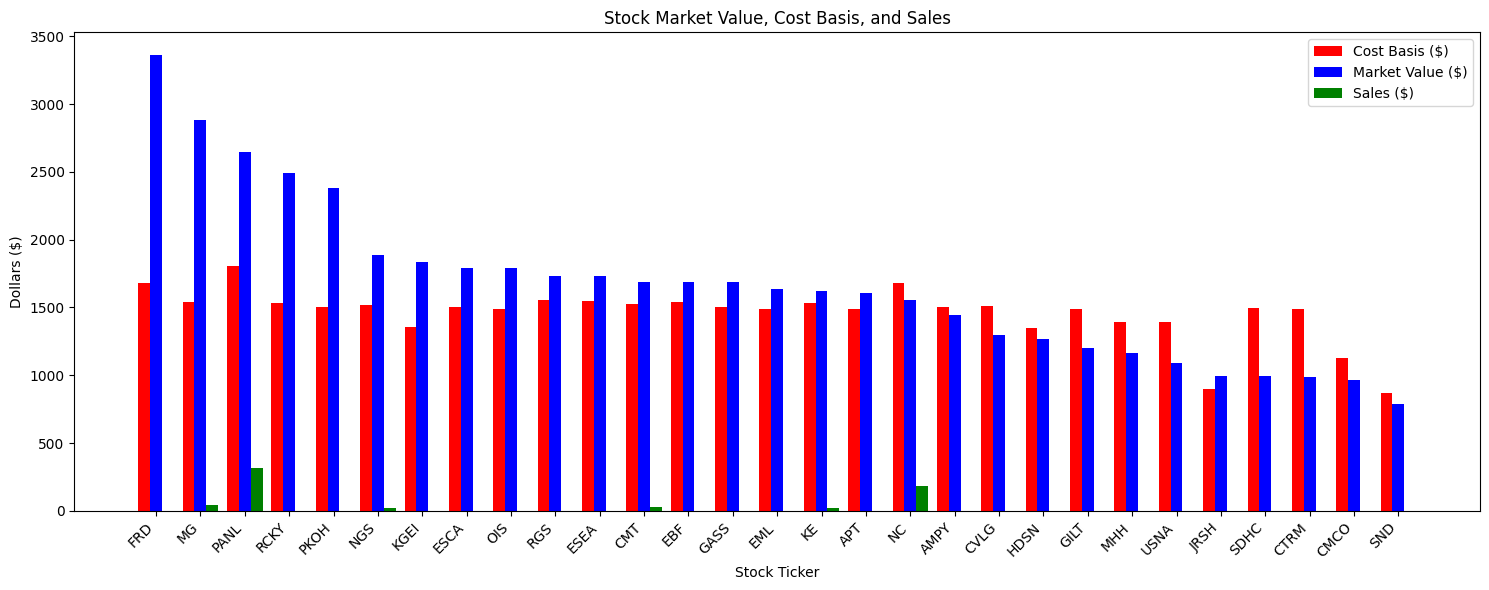

In [7]:
# Compute effective annual rate of return per stock and for the portfolio
stock_return_df = cost_basis_df.merge(
    aaii_df[['Ticker', 'CurrentPrice($)']],
    on='Ticker',
    how='left'
).copy()

stock_return_df['Market Value'] = stock_return_df['Total Shares'] * stock_return_df['CurrentPrice($)']
stock_return_df['Cost Basis'] = stock_return_df['Total Buy Cost']
stock_return_df['Sales'] = stock_return_df['Total Sell Proceeds']

stock_transactions = {ticker: group for ticker, group in filtered_transactions.groupby('Symbol')}
stock_return_df['Effective Annual Return'] = stock_return_df.apply(
    lambda row: compute_effective_annual_rate(
        stock_transactions.get(row['Ticker'], pd.DataFrame()).get('Amount $', pd.Series(dtype=float)).astype(float).to_numpy(),
        stock_transactions.get(row['Ticker'], pd.DataFrame()).get('Activity/Trade Date', pd.Series(dtype='datetime64[ns]')).tolist(),
        row['Market Value'],
        reference_date,
    ),
    axis=1,
)

portfolio_current_value = stock_return_df['Market Value'].sum()
portfolio_effective_annual_return = compute_portfolio_effective_annual_return(
    filtered_transactions,
    portfolio_current_value,
    reference_date,
)

print('Per-stock effective annual return:')
print(stock_return_df[['Ticker', 'Effective Annual Return']].sort_values('Effective Annual Return', ascending=False).head(10))
print(f'\nPortfolio effective annual return: {portfolio_effective_annual_return:.6%}')

# Plot market value, cost basis, and sales by stock
plot_df = stock_return_df.copy()
plot_df = plot_df.sort_values('Market Value', ascending=False).reset_index(drop=True)

x = np.arange(len(plot_df))
bar_width = 0.8 / 3

fig, ax = plt.subplots(figsize=(15, 6), layout='constrained')
ax.bar(x - bar_width, plot_df['Cost Basis'], width=bar_width, color='r', label='Cost Basis ($)')
ax.bar(x, plot_df['Market Value'], width=bar_width, color='b', label='Market Value ($)')
ax.bar(x + bar_width, plot_df['Sales'], width=bar_width, color='g', label='Sales ($)')

ax.set_xticks(x)
ax.set_xticklabels(plot_df['Ticker'], rotation=45, ha='right')
ax.set_ylabel('Dollars ($)')
ax.set_xlabel('Stock Ticker')
ax.set_title('Stock Market Value, Cost Basis, and Sales')
ax.legend()
plt.tight_layout()
plt.show()

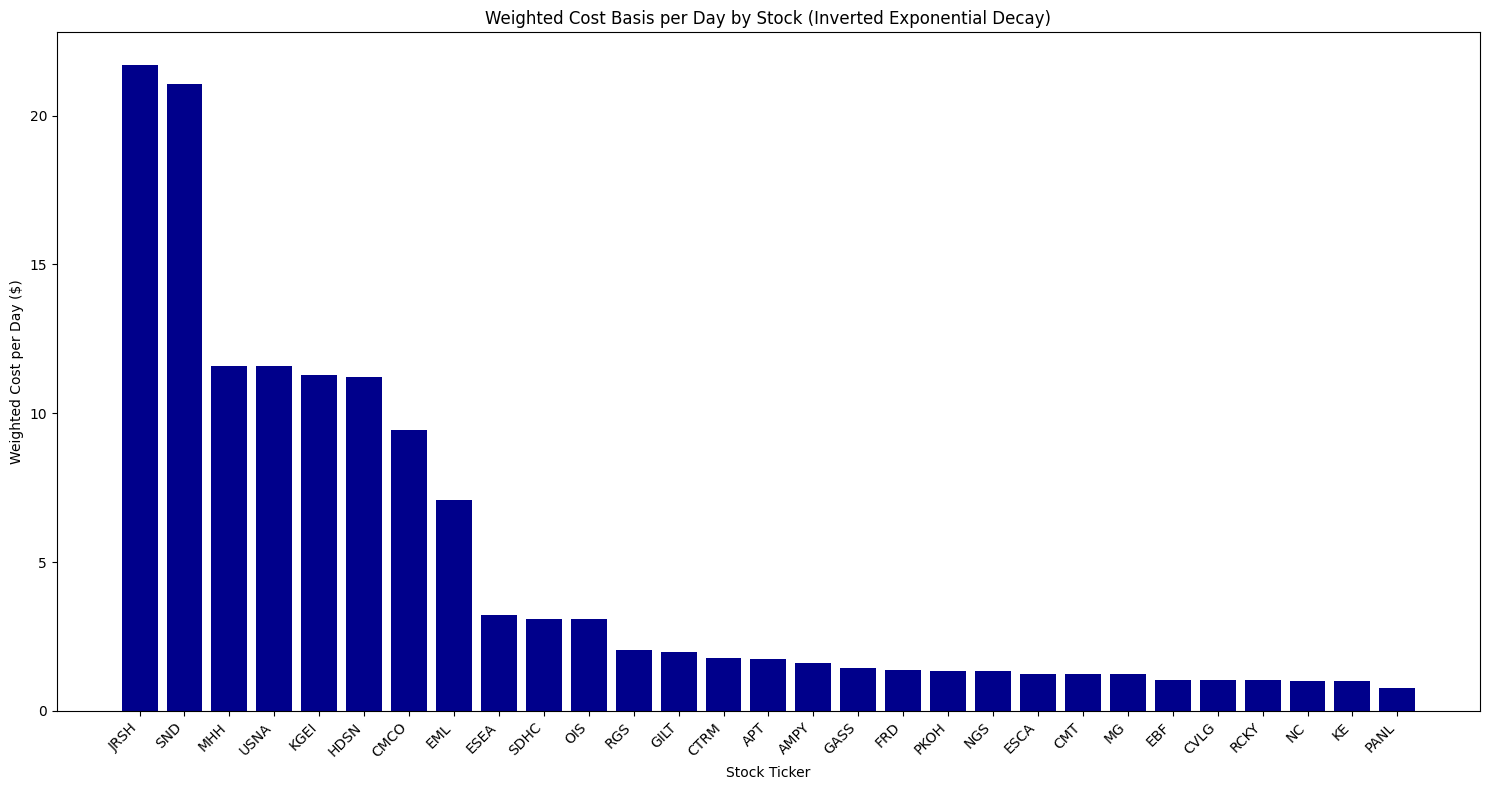

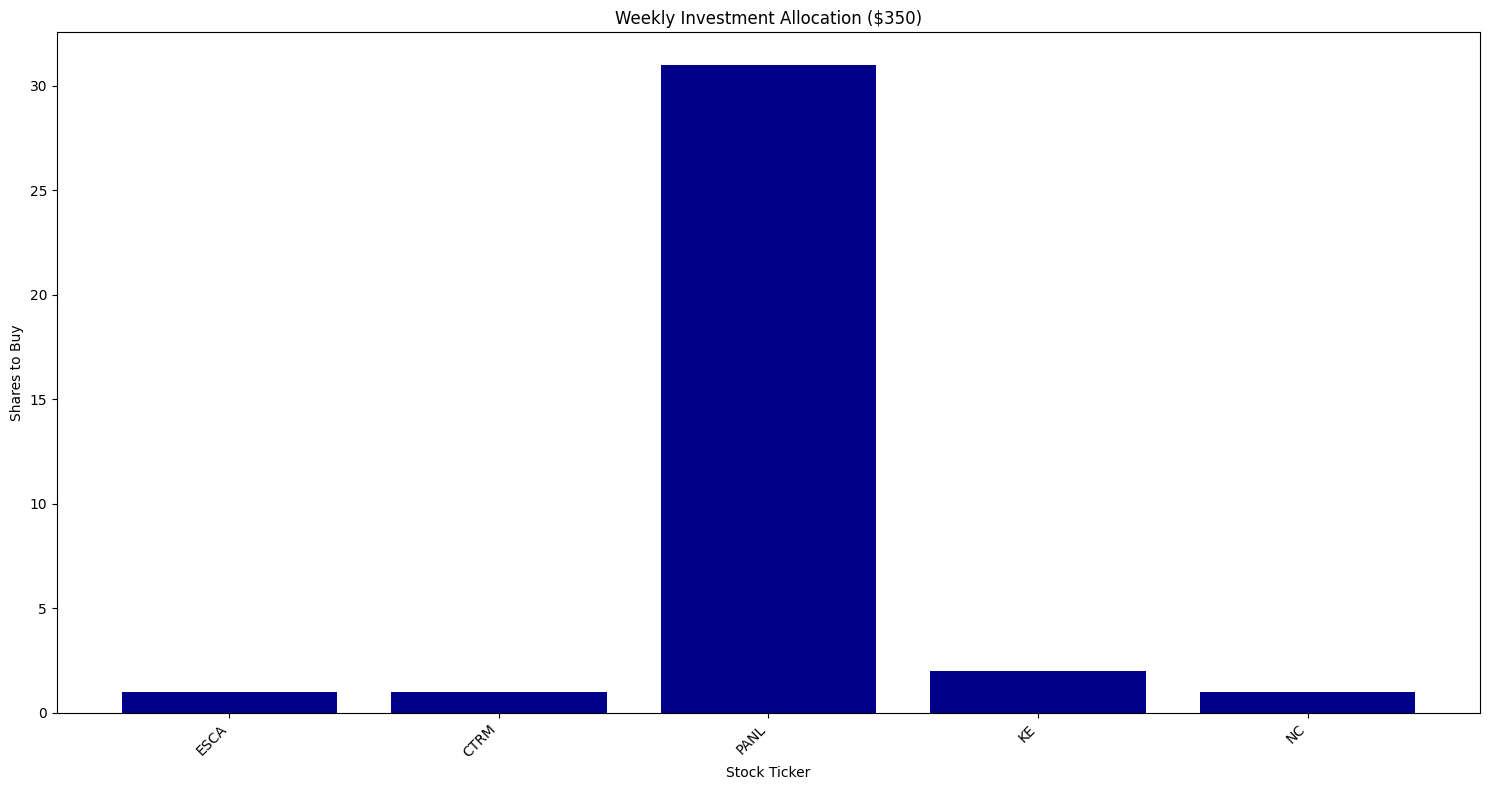

Updated cost basis after purchases:
   Ticker  Weighted Cost per Day  Net Cost  Total Shares
2    JRSH              21.715238    898.40       162.000
1     SND              21.064071    871.46       165.000
21    MHH              11.601198   1393.30       183.000
20   USNA              11.596285   1392.71        78.000
11   KGEI              11.281047   1354.85       252.000
15   HDSN              11.223345   1347.92       236.000
13   CMCO               9.433156   1123.75        71.169
10    EML               7.072533   1485.89        67.523
17   ESEA               3.207308   1549.13        25.996
18   SDHC               3.091428   1493.16        95.000
16    OIS               3.086542   1490.80       208.000
6     RGS               2.041494   1557.66        59.000
8    GILT               1.971746   1490.64       161.000
22    APT               1.753896   1485.55       289.000
9    CTRM               1.716893   1491.98       618.000
3    AMPY               1.594487   1506.79       314

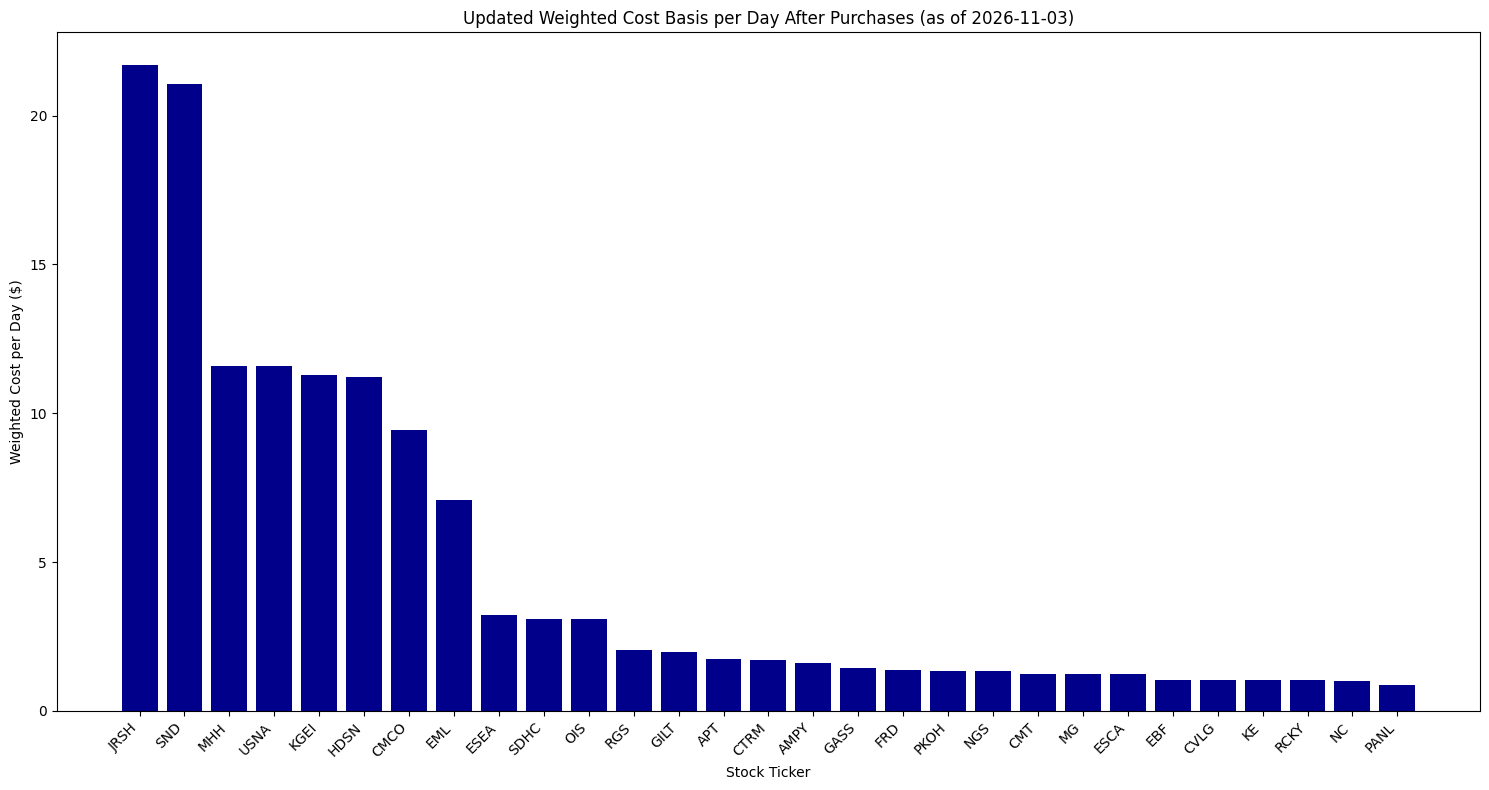

In [8]:
# Plot weighted cost per day (with inverted exponential decay)
plt.figure(figsize=(15, 8))

plot_df3 = cost_basis_df.sort_values('Weighted Cost per Day', ascending=False)

plt.bar(plot_df3['Ticker'], plot_df3['Weighted Cost per Day'], color='darkblue')
plt.ylabel('Weighted Cost per Day ($)')
plt.xlabel('Stock Ticker')
plt.title('Weighted Cost Basis per Day by Stock (Inverted Exponential Decay)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Plot weekly investment allocation
plt.figure(figsize=(15, 8))

if len(allocation_df) > 0:
    plt.bar(allocation_df['Ticker'], allocation_df['Shares to Buy'], color='darkblue')
    plt.ylabel('Shares to Buy')
    plt.xlabel('Stock Ticker')
    plt.title(f'Weekly Investment Allocation (${weekly_new_amount})')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No allocation - unable to buy any shares with the given amount")

# Use the post-allocation cost basis for the updated plot so the purchases are reflected
updated_cost_basis_df = updated_cost_basis_df.copy()
updated_cost_basis_df['Weighted Cost per Day'] = updated_cost_basis_df['Weighted Cost per Day'].fillna(0)
updated_cost_basis_df = updated_cost_basis_df.sort_values('Weighted Cost per Day', ascending=False)

print("Updated cost basis after purchases:")
print(updated_cost_basis_df[['Ticker', 'Weighted Cost per Day', 'Net Cost', 'Total Shares']])

# Plot updated weighted cost per day after purchases from the updated cost basis frame
if len(updated_cost_basis_df) > 0:
    print(f"Plotting updated weighted cost, min: {updated_cost_basis_df['Weighted Cost per Day'].min()}, max: {updated_cost_basis_df['Weighted Cost per Day'].max()}")

    # Check if all values are zero or very small
    if updated_cost_basis_df['Weighted Cost per Day'].max() < 0.01:
        print("Warning: All weighted cost values are very small (near zero)")
        print("This is expected because new purchases at reference_date have weight = 0 in inverted decay formula")
        print("Let's plot Net Cost instead to see the actual values:")

        plt.figure(figsize=(15, 8))
        net_cost_plot_df = updated_cost_basis_df.sort_values('Net Cost', ascending=False)
        plt.bar(net_cost_plot_df['Ticker'], net_cost_plot_df['Net Cost'], color='darkblue')
        plt.ylabel('Net Cost ($)')
        plt.xlabel('Stock Ticker')
        plt.title(f'Net Cost After Purchases (as of {reference_date.date()})')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
    else:
        plt.figure(figsize=(15, 8))
        plt.bar(updated_cost_basis_df['Ticker'], updated_cost_basis_df['Weighted Cost per Day'], color='darkblue')
        plt.ylabel('Weighted Cost per Day ($)')
        plt.xlabel('Stock Ticker')
        plt.title(f'Updated Weighted Cost Basis per Day After Purchases (as of {reference_date.date()})')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
else:
    print("No updated cost basis data to plot")

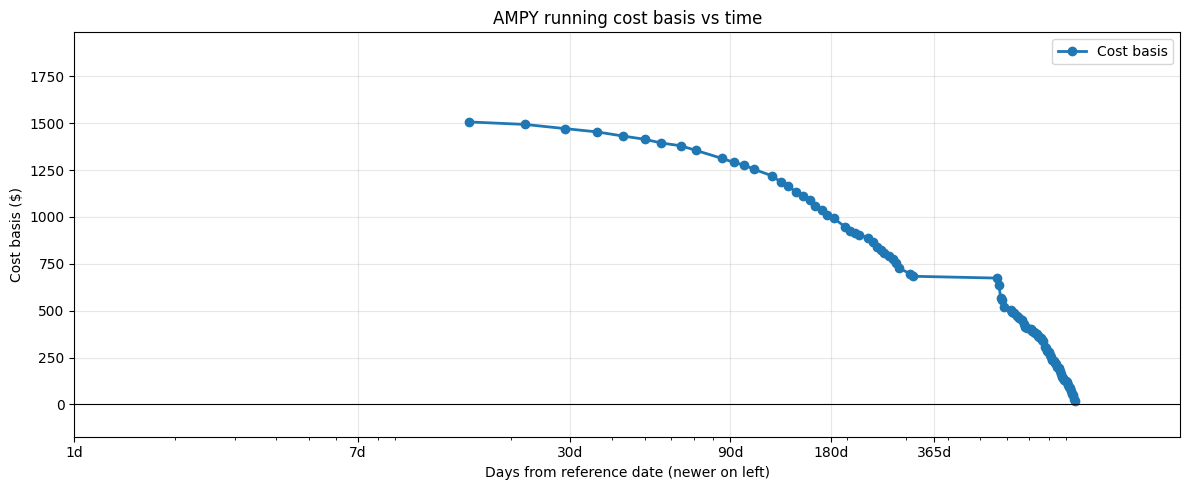

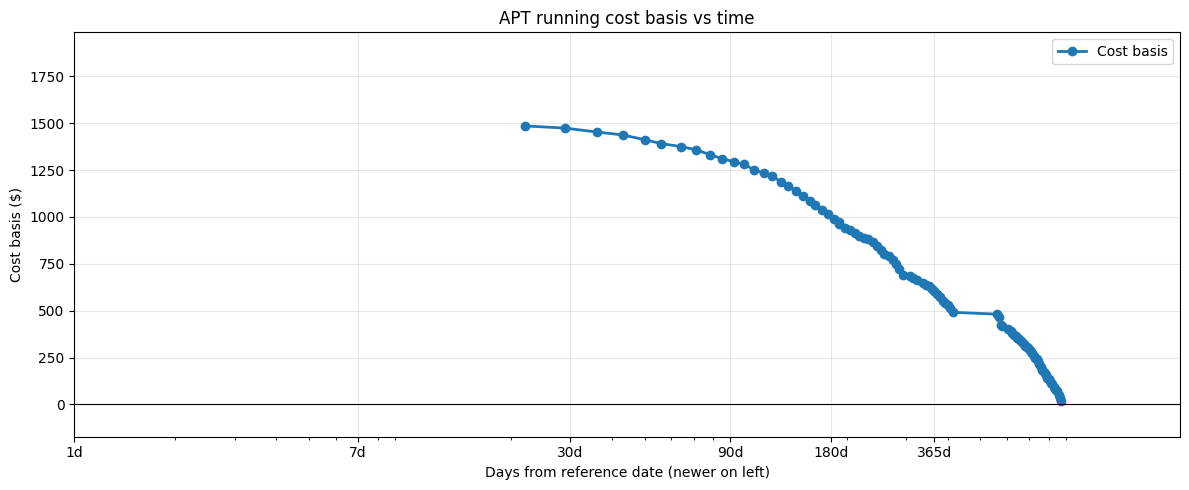

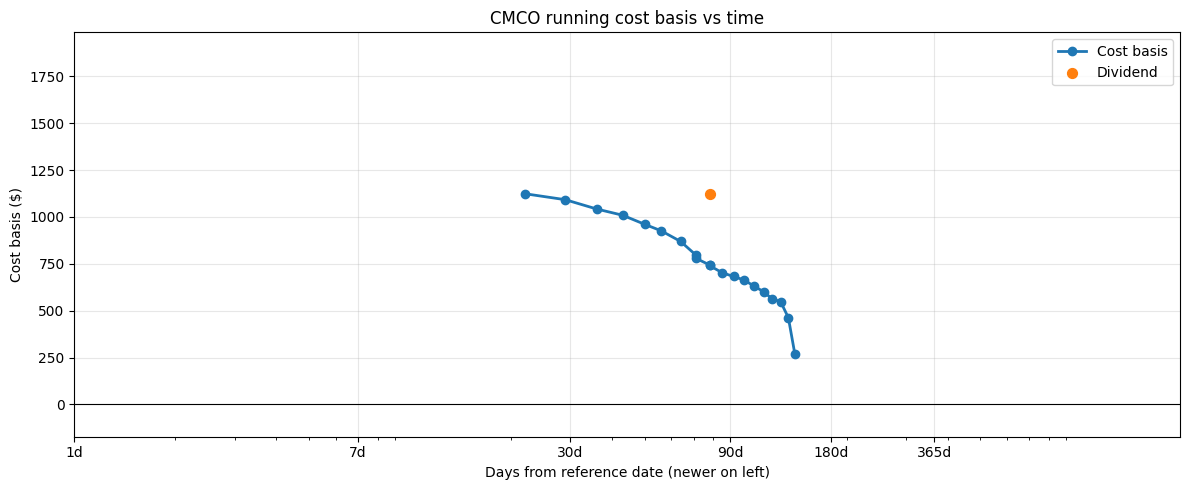

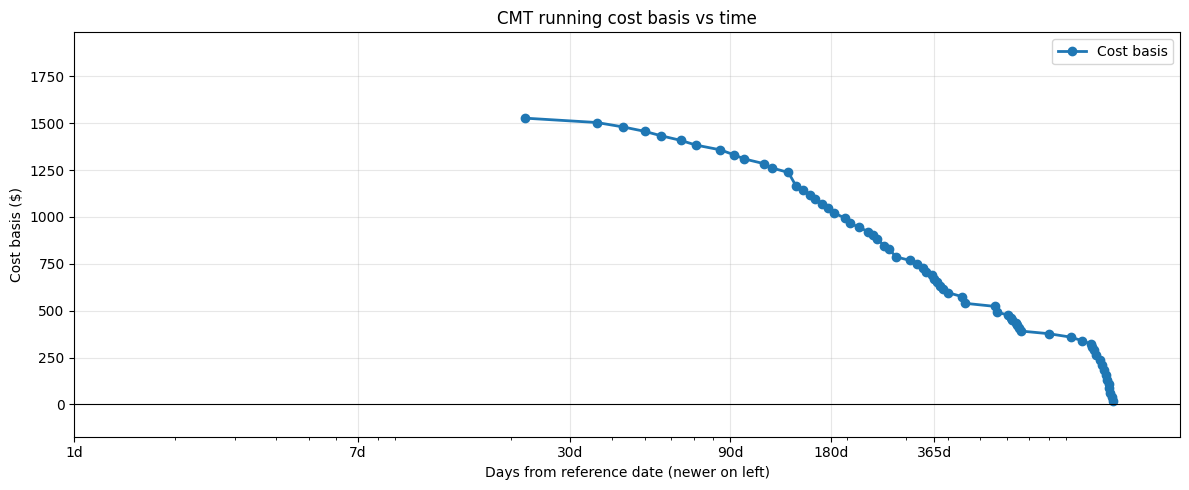

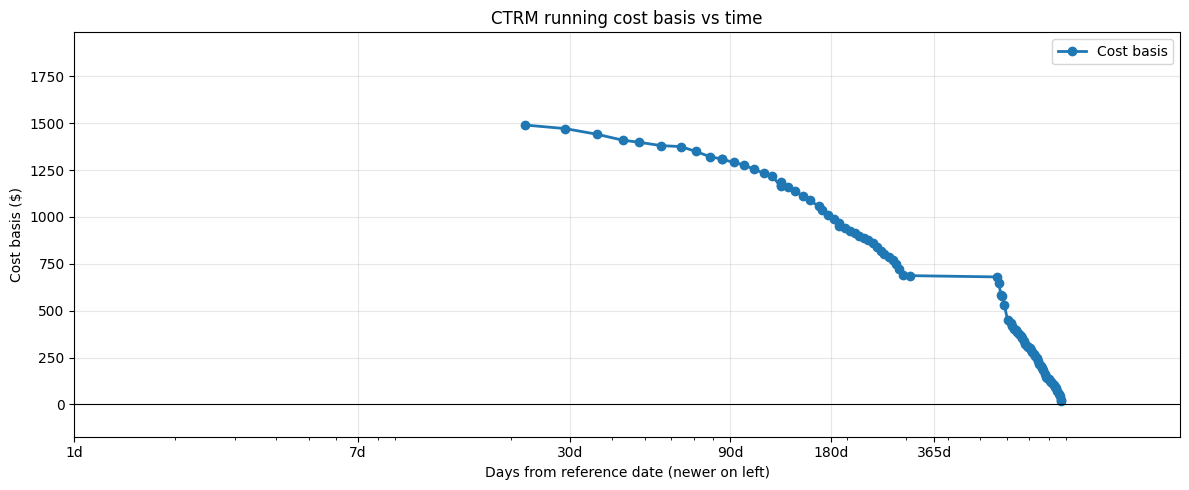

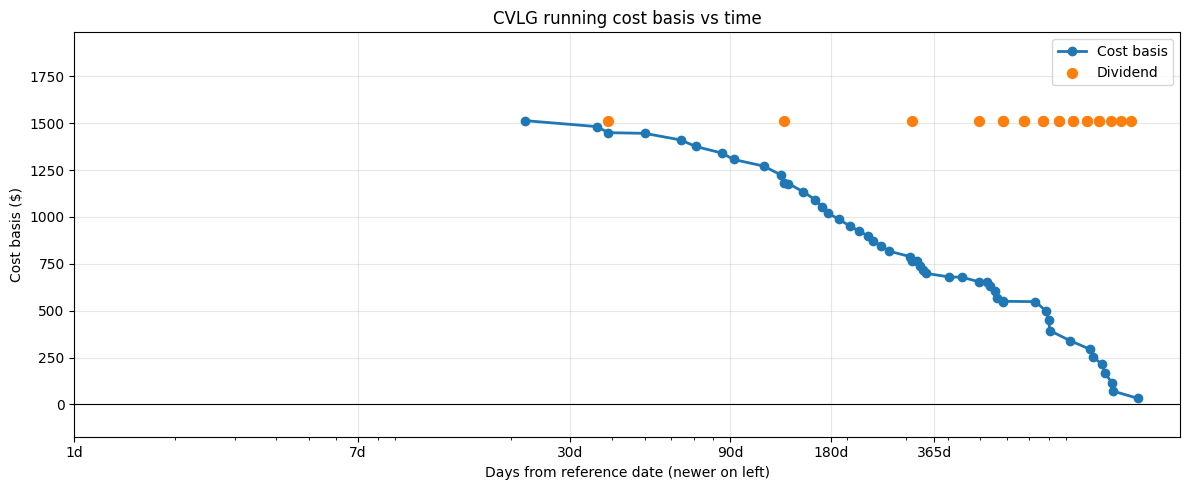

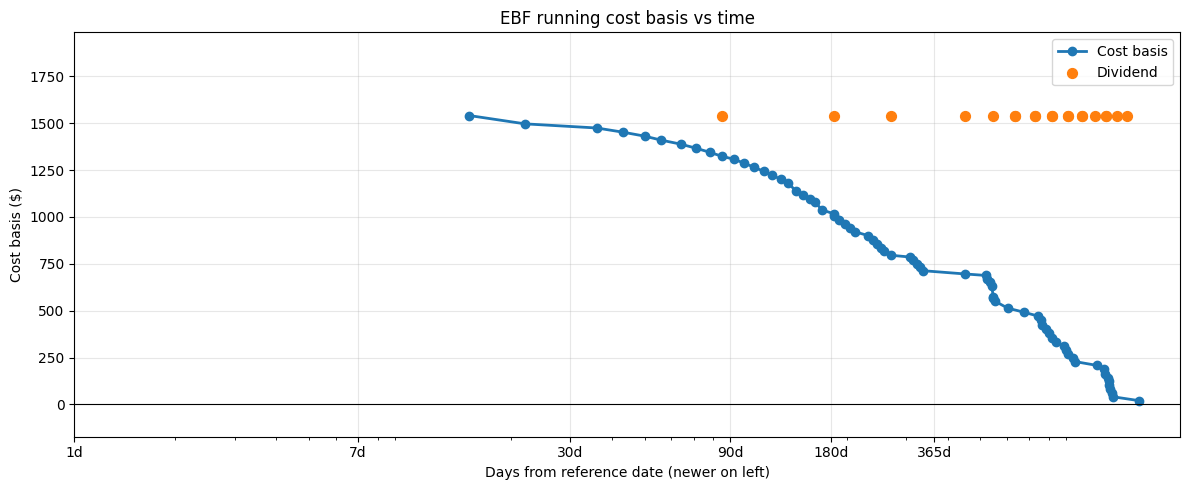

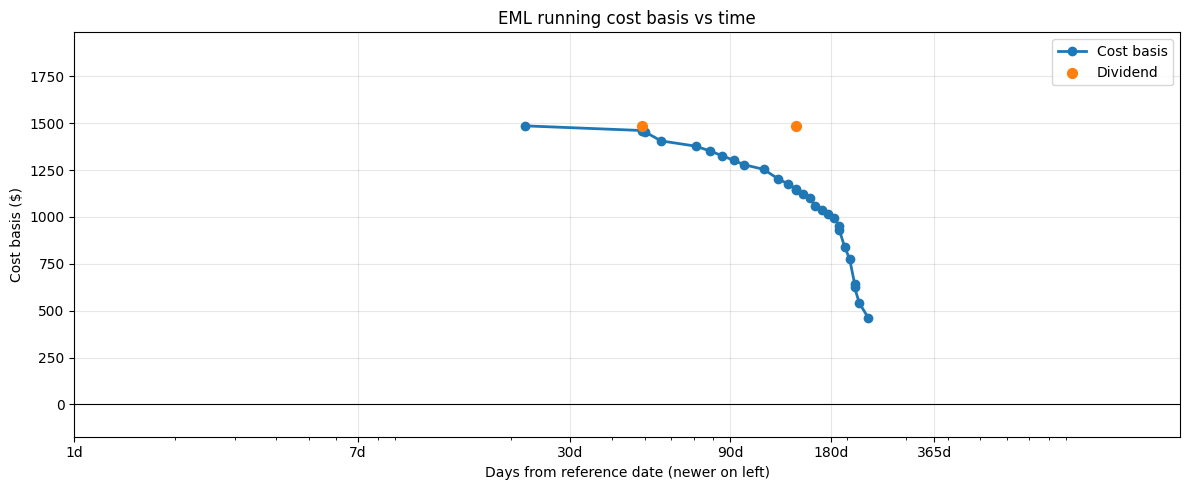

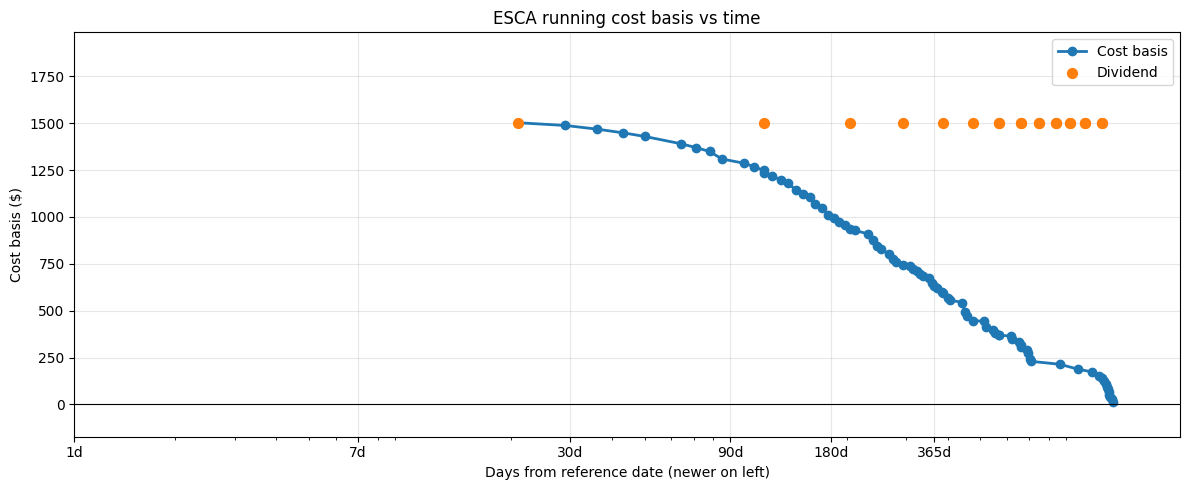

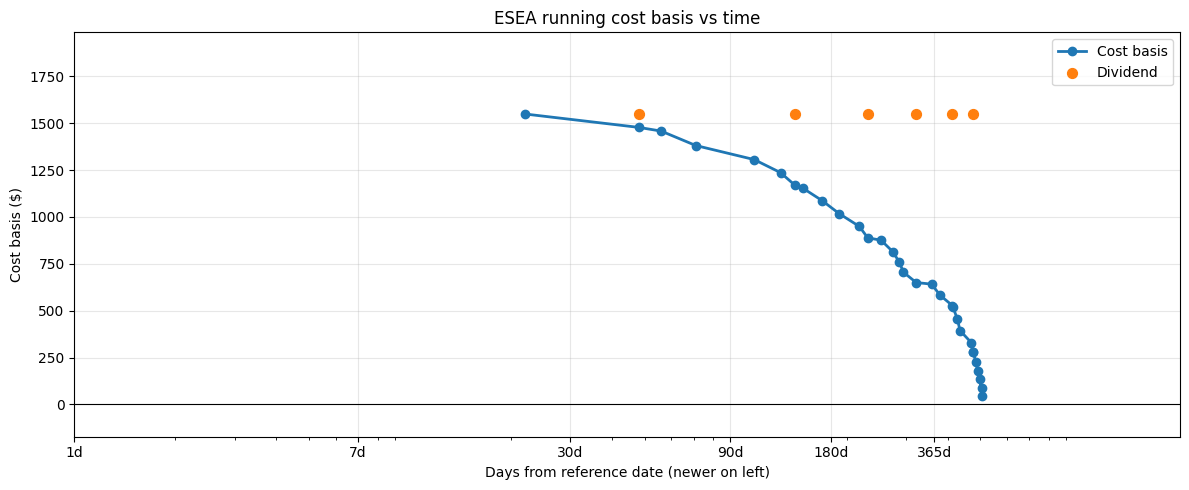

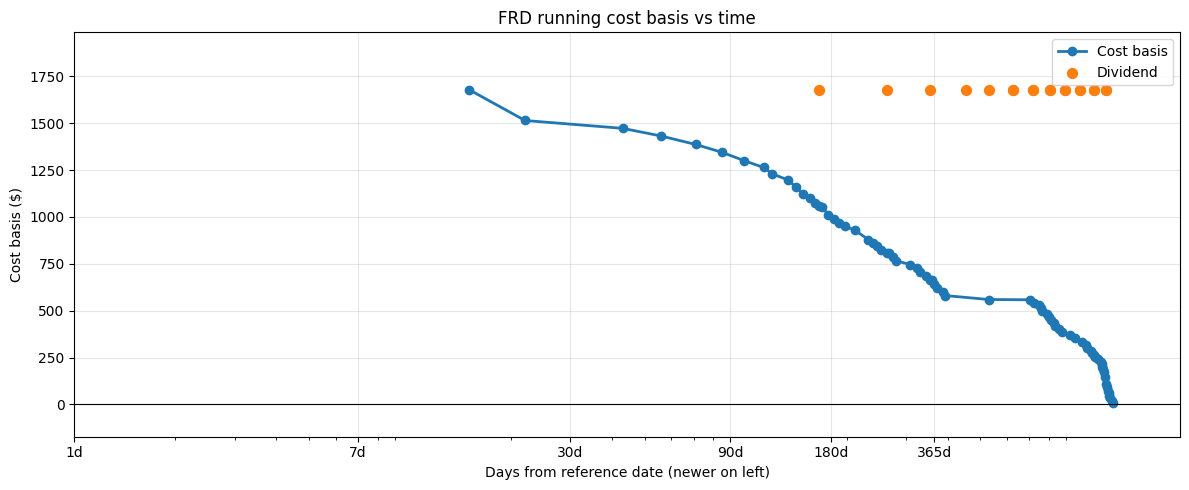

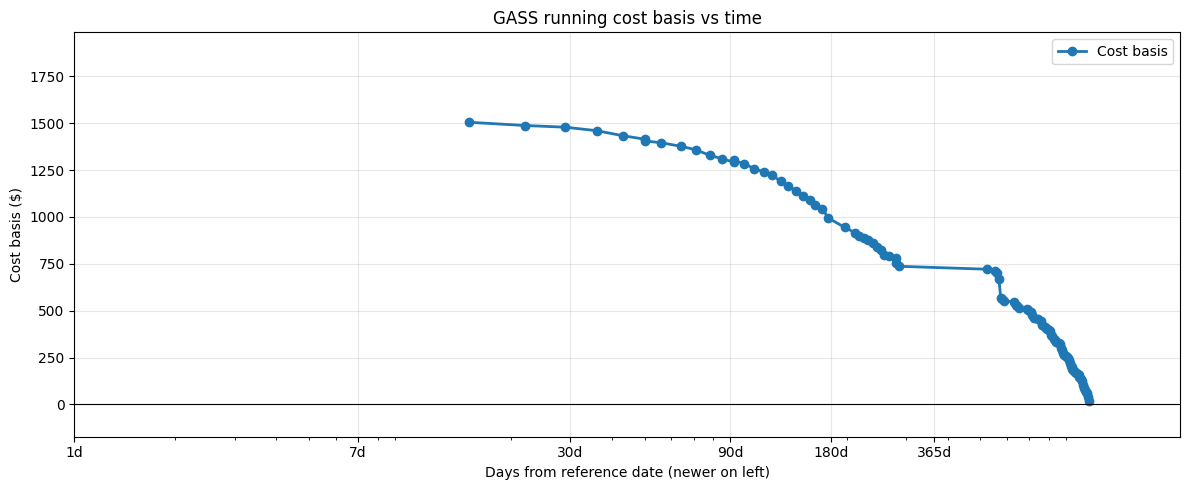

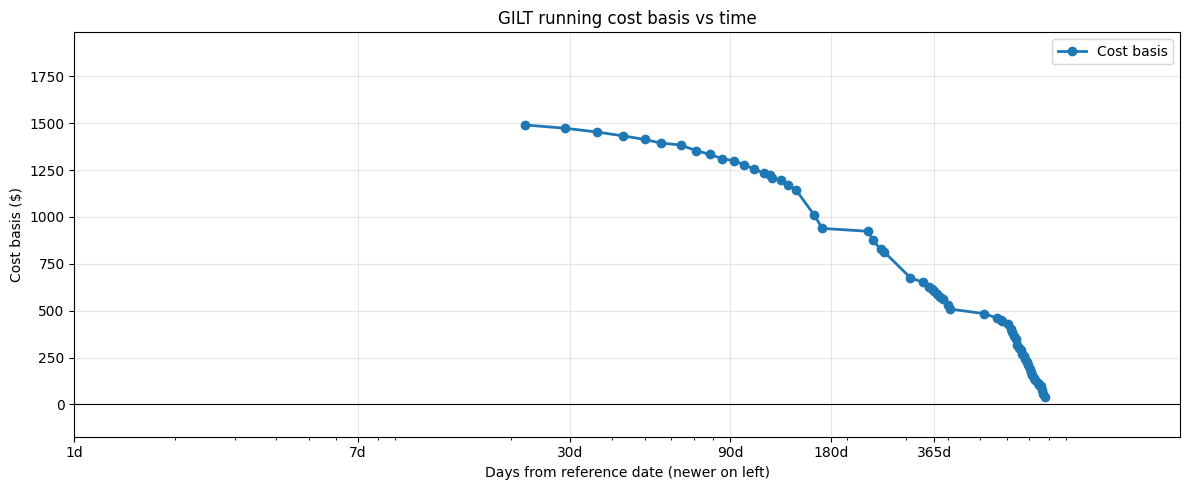

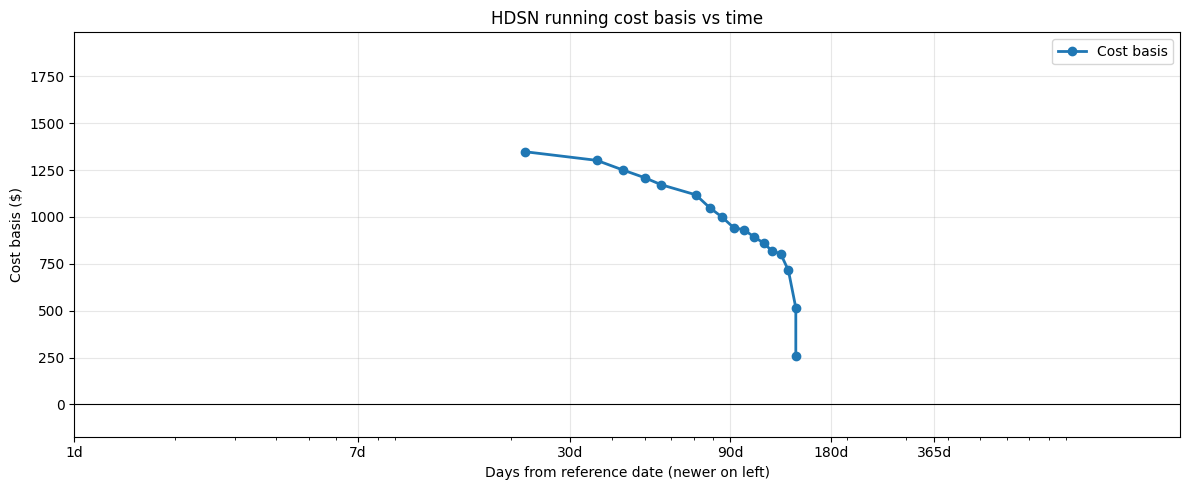

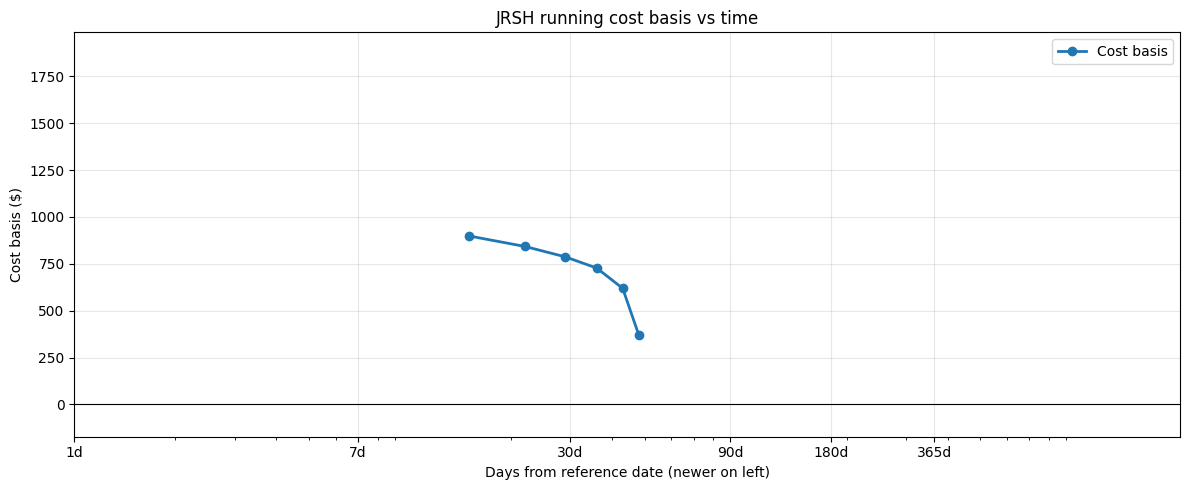

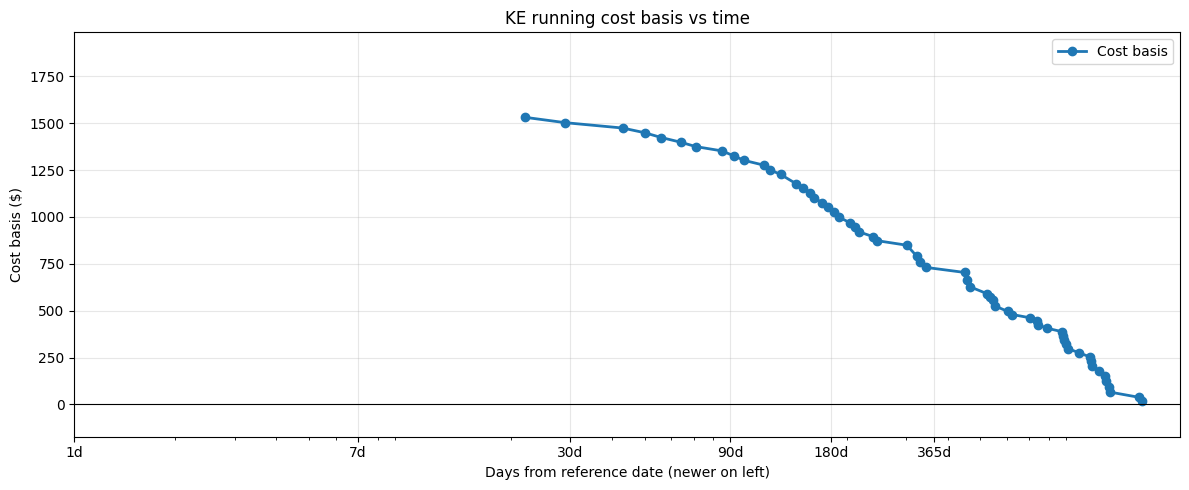

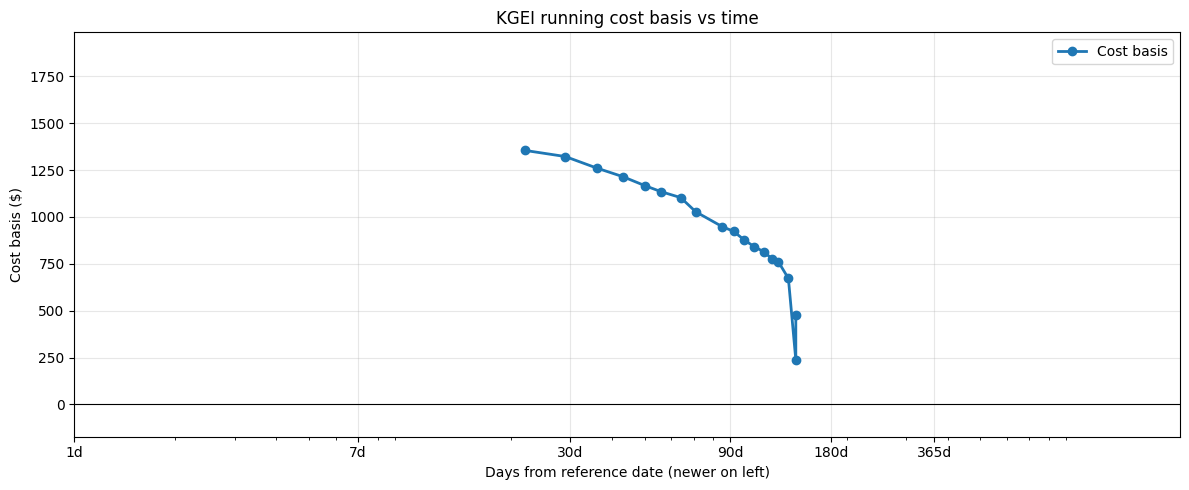

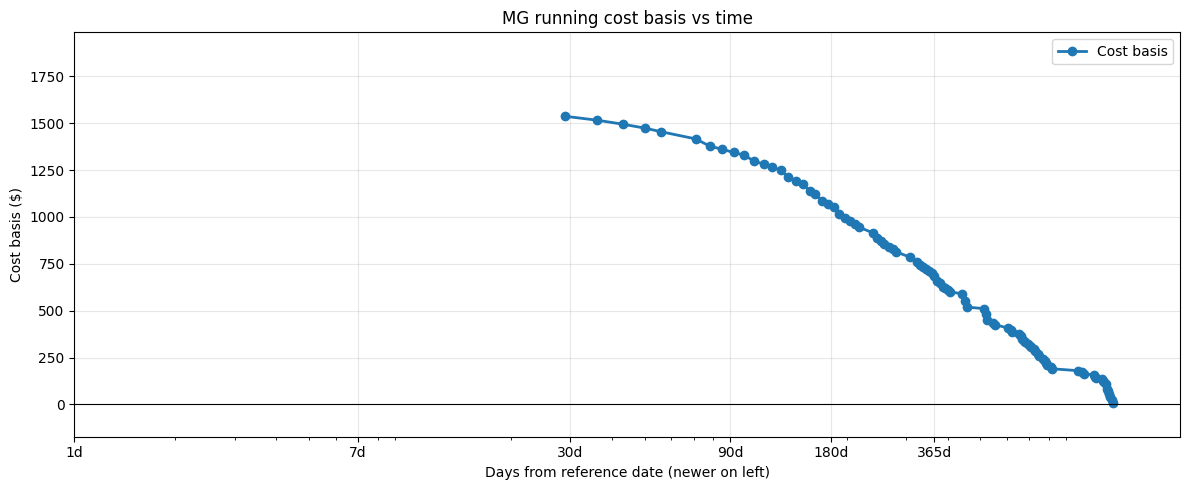

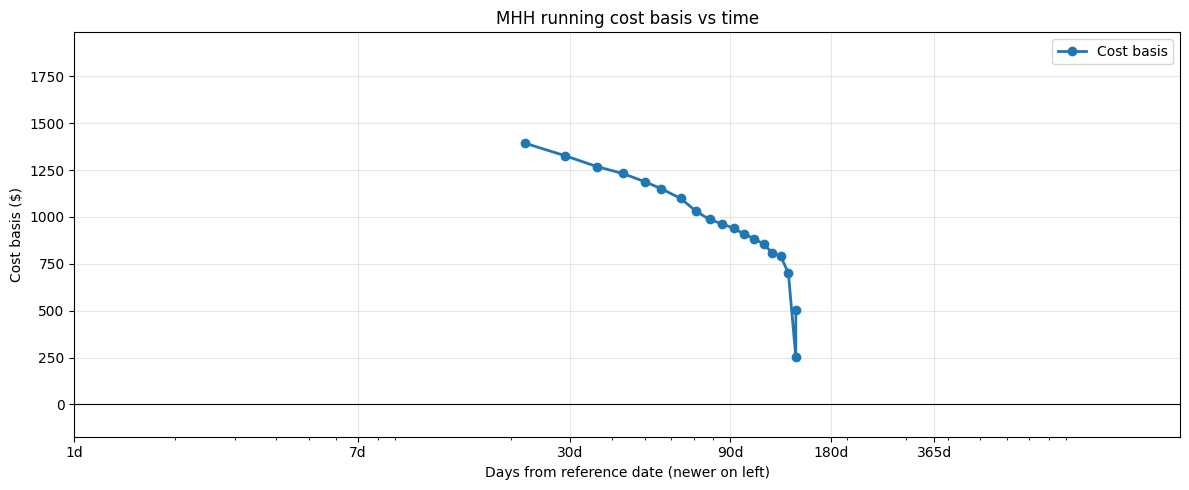

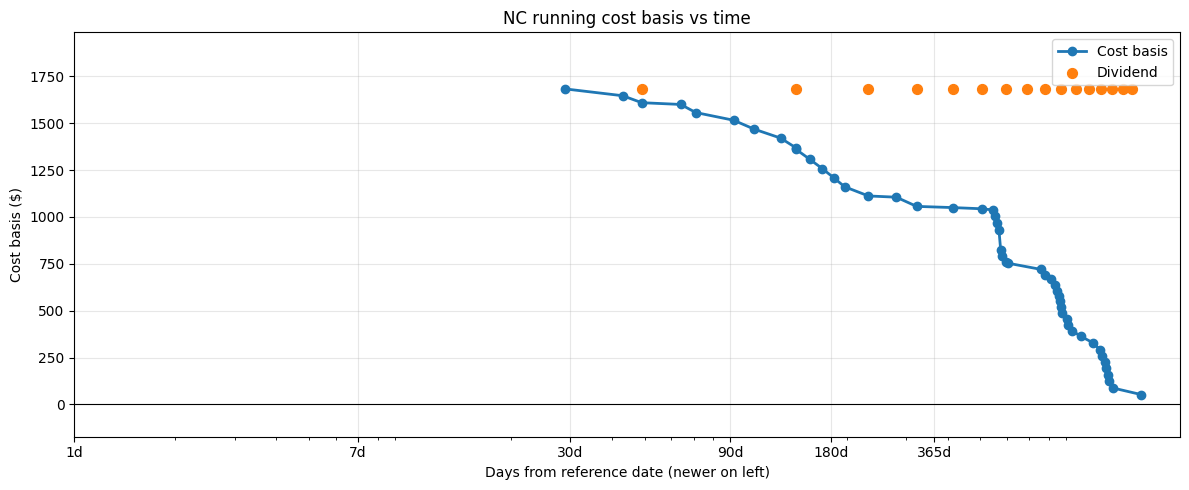

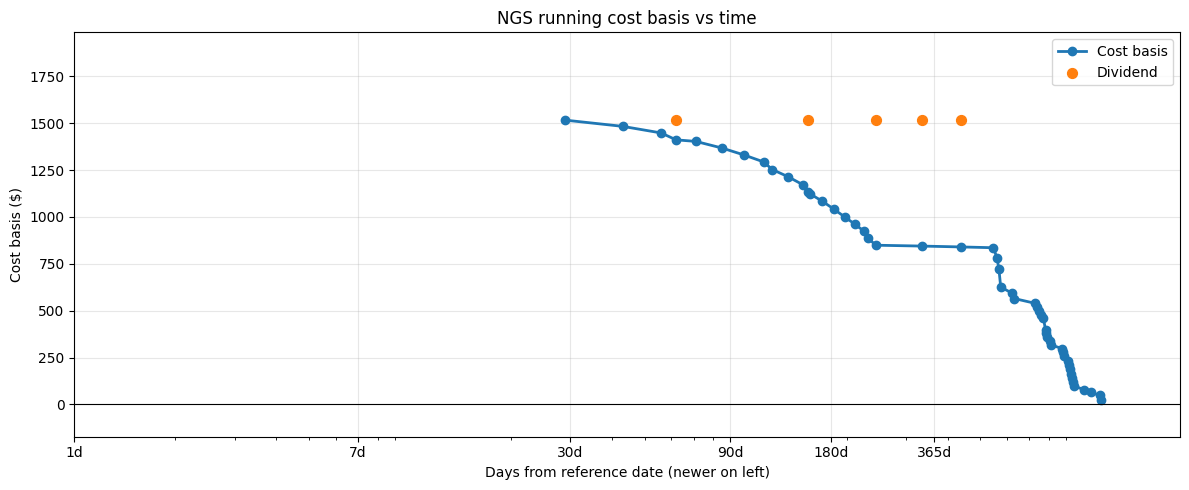

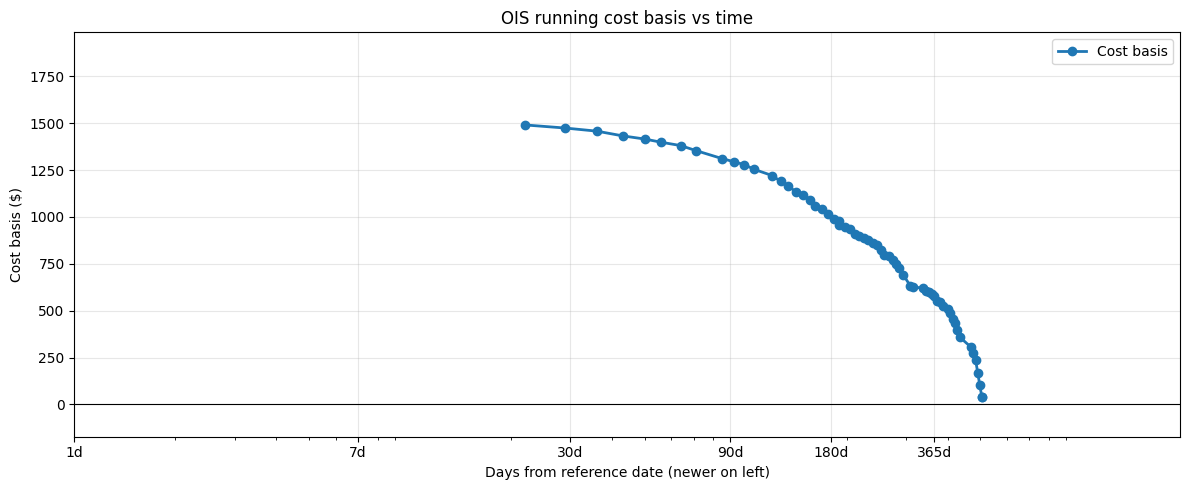

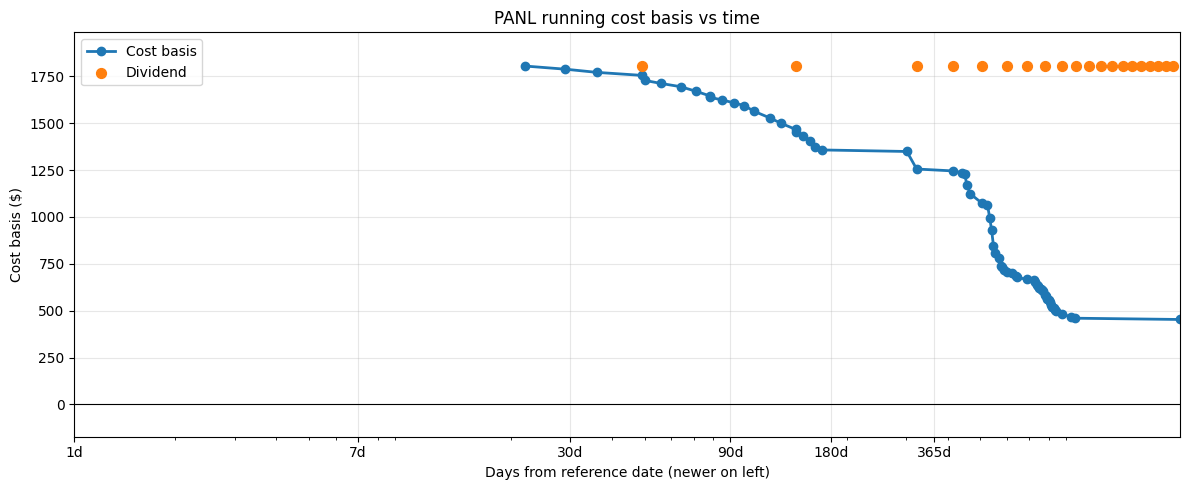

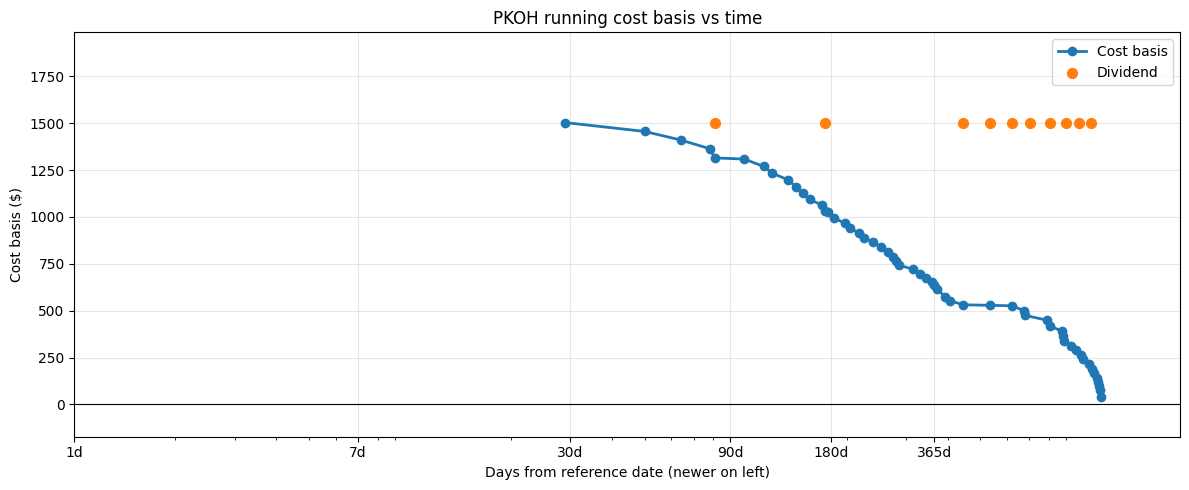

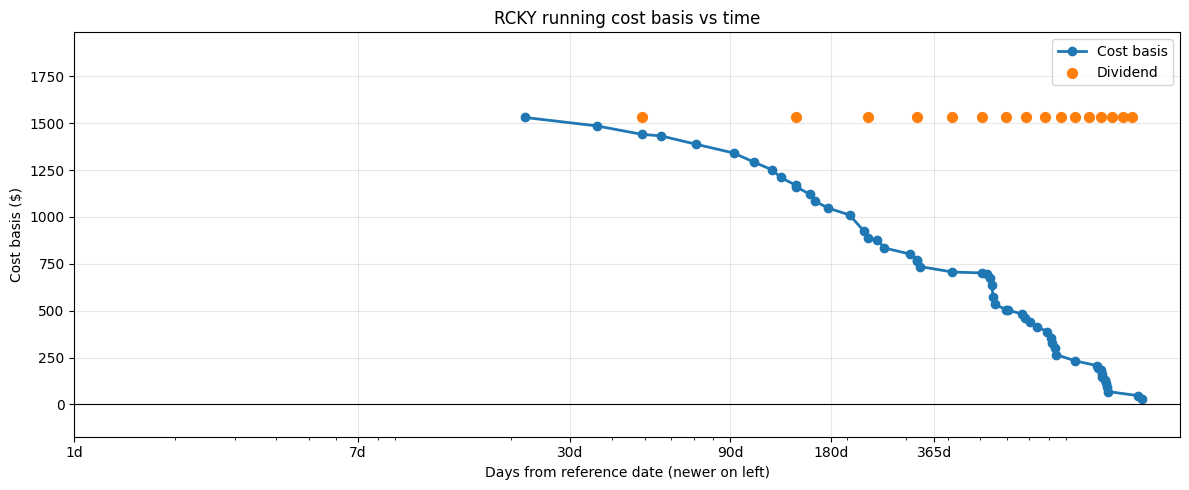

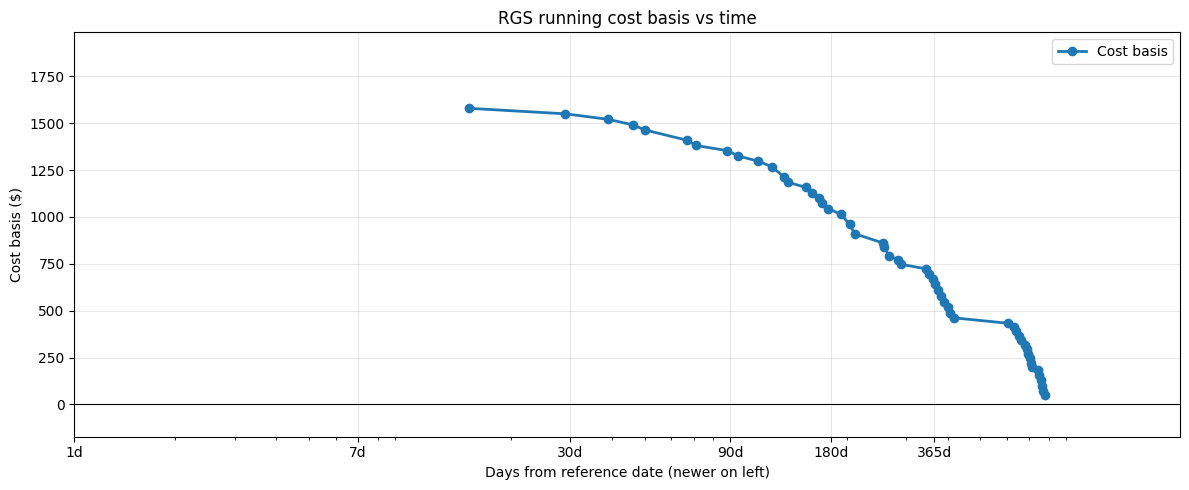

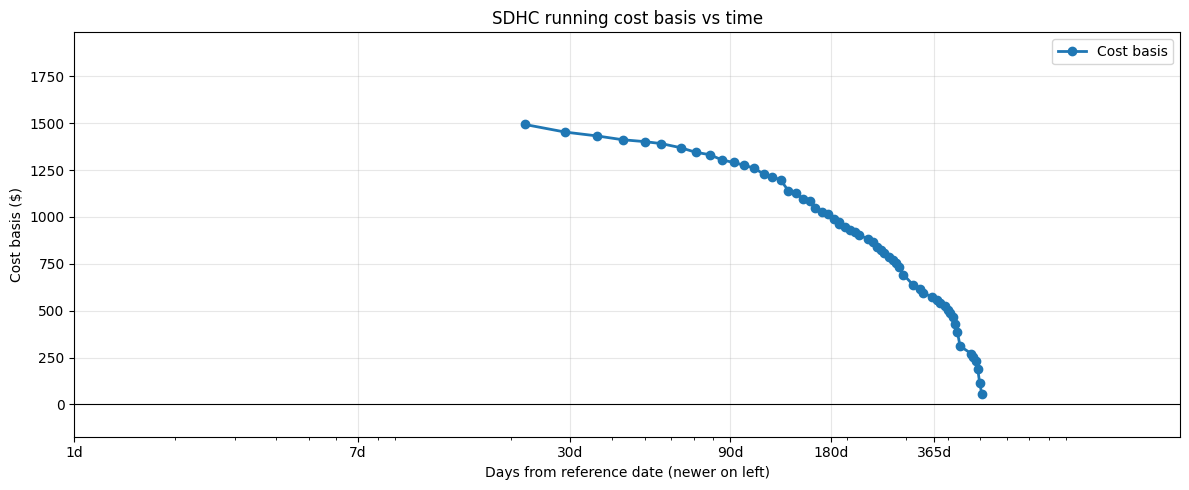

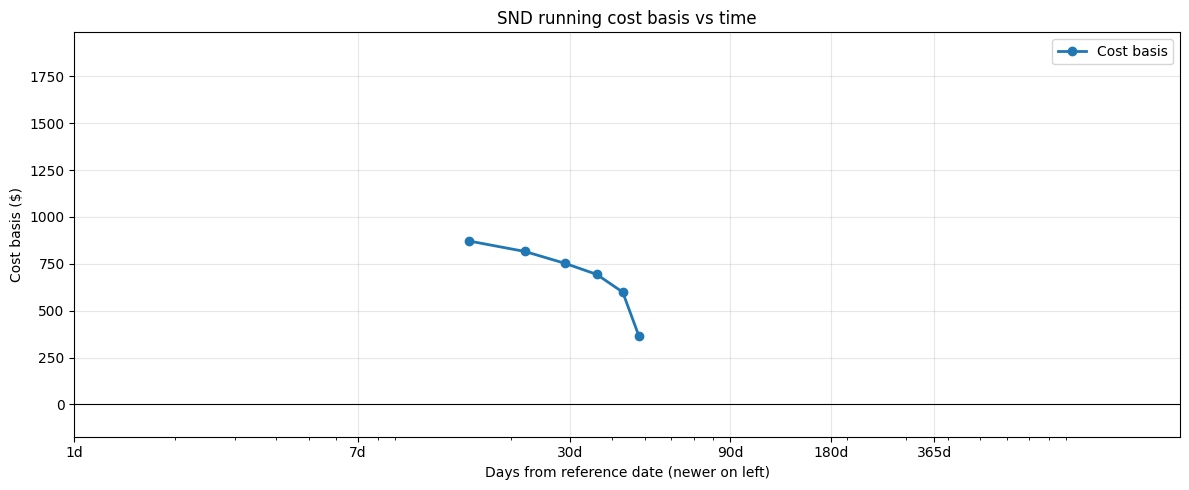

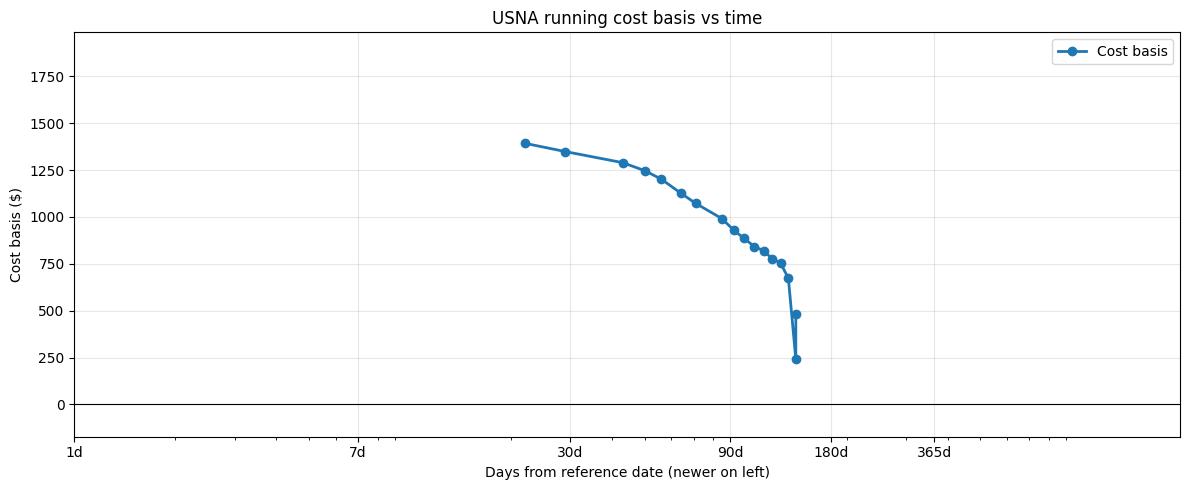

In [ ]:
# Plot running cost basis vs time relative to the reference date
# Show 5 stocks per chart, with newer transactions on the left.
cash_flow_df = filtered_transactions[["Symbol", "Activity/Trade Date", "Amount $", "Quantity #"]].copy()
cash_flow_df["Amount $"] = pd.to_numeric(cash_flow_df["Amount $"], errors="coerce")
cash_flow_df["Quantity #"] = pd.to_numeric(cash_flow_df["Quantity #"], errors="coerce")
cash_flow_df = cash_flow_df.dropna(subset=["Amount $"]).copy()


def classify_cash_flow(row):
    amount = row["Amount $"]
    quantity = row["Quantity #"]

    if pd.isna(amount):
        return None
    if amount < 0:
        return "buy"
    if amount > 0:
        if pd.isna(quantity) or quantity == 0:
            return "dividend"
        if quantity < 0:
            return "sell"
    return None


cash_flow_df["Flow Type"] = cash_flow_df.apply(classify_cash_flow, axis=1)
cash_flow_df = cash_flow_df[cash_flow_df["Flow Type"].notna()].copy()

# Cost basis only accumulates purchases; dividends are shown separately.
cash_flow_df["Basis Impact"] = 0.0
cash_flow_df.loc[cash_flow_df["Flow Type"] == "buy", "Basis Impact"] = cash_flow_df.loc[cash_flow_df["Flow Type"] == "buy", "Amount $"].abs()

all_cost_basis_values = []
all_days_from_reference = []
stock_plot_data = []
for ticker, group in cash_flow_df.groupby("Symbol"):
    plot_df = group.sort_values("Activity/Trade Date").copy()
    buy_df = plot_df[plot_df["Flow Type"] == "buy"].copy()
    dividend_df = plot_df[plot_df["Flow Type"] == "dividend"].copy()
    if buy_df.empty:
        continue
    buy_df["Cumulative Cost Basis"] = buy_df["Basis Impact"].cumsum()
    buy_df["Days from reference"] = (reference_date - buy_df["Activity/Trade Date"]).dt.days.abs().clip(lower=1)
    buy_df = buy_df.sort_values(["Days from reference", "Activity/Trade Date"], ascending=[True, True]).reset_index(drop=True)
    all_cost_basis_values.append(buy_df["Cumulative Cost Basis"].to_numpy())
    all_days_from_reference.append(buy_df["Days from reference"].to_numpy())
    stock_plot_data.append((ticker, buy_df, dividend_df))

common_y_limits = None
common_x_limits = None
if all_cost_basis_values:
    flat_values = np.concatenate(all_cost_basis_values)
    y_min = float(np.min(flat_values))
    y_max = float(np.max(flat_values))
    y_padding = max((y_max - y_min) * 0.10, 1.0)
    common_y_limits = (y_min - y_padding, y_max + y_padding)

shared_tick_values = np.array([1.0, 2.0, 4.0, 7.0, 30.0, 90.0, 180.0, 365.0, 730.0, 1460.0], dtype=float)
if all_days_from_reference:
    flat_days = np.concatenate(all_days_from_reference)
    x_min = float(np.min(flat_days))
    x_max = float(np.max(flat_days))
    common_x_limits = (x_min, x_max)
    shared_tick_values = np.unique(np.concatenate([shared_tick_values, np.array([x_max], dtype=float)]))

for batch_start in range(0, len(stock_plot_data), 5):
    batch = stock_plot_data[batch_start:batch_start + 5]
    fig, ax = plt.subplots(figsize=(14, 6))

    plot_colors = ["tab:blue", "tab:green", "tab:red", "tab:purple", "tab:orange"]
    for idx, (ticker, buy_df, dividend_df) in enumerate(batch):
        x_values = buy_df["Days from reference"].to_numpy(dtype=float)
        ax.plot(
            x_values,
            buy_df["Cumulative Cost Basis"],
            color=plot_colors[idx % len(plot_colors)],
            linewidth=2,
            marker="o",
            label=ticker,
        )
        if not dividend_df.empty:
            dividend_df = dividend_df.sort_values("Activity/Trade Date", ascending=True).copy()
            dividend_days = (reference_date - dividend_df["Activity/Trade Date"]).dt.days.abs().clip(lower=1)
            dividend_y = np.interp(
                dividend_days.to_numpy(dtype=float),
                x_values,
                buy_df["Cumulative Cost Basis"].to_numpy(dtype=float),
                left=buy_df["Cumulative Cost Basis"].iloc[0],
                right=buy_df["Cumulative Cost Basis"].iloc[-1],
            )
            ax.scatter(
                dividend_days.to_numpy(dtype=float),
                dividend_y,
                color="tab:orange",
                s=45,
                label=f"{ticker} dividend",
                zorder=5,
            )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"Running cost basis vs time ({batch_start + 1}-{min(batch_start + 5, len(stock_plot_data))} of {len(stock_plot_data)} stocks)")
    ax.set_xlabel("Days from reference date (newer on left)")
    ax.set_ylabel("Cost basis ($)")
    ax.grid(True, alpha=0.3)
    ax.set_xscale("log")
    if common_x_limits is not None:
        ax.set_xlim(common_x_limits[1], common_x_limits[0])
        ax.invert_xaxis()
    if common_y_limits is not None:
        ax.set_ylim(common_y_limits)
    ax.set_xticks(shared_tick_values)
    ax.set_xticklabels([
        "1d" if v == 1.0 else
        "2d" if v == 2.0 else
        "4d" if v == 4.0 else
        "7d" if v == 7.0 else
        "30d" if v == 30.0 else
        "90d" if v == 90.0 else
        "180d" if v == 180.0 else
        "1y" if v >= 365.0 and v < 730.0 else
        "2y" if v >= 730.0 and v < 1460.0 else
        "4y" if v >= 1460.0 else
        f"{int(v)}d"
        for v in shared_tick_values
    ])
    ax.legend(title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
